to do
- define PCA
- save figures as ps or pdf
- make a table specifying which parameters were used to solve the gilmore-akulichev model.
- overlay graphs and spectrums
- plot bar charts for the cluster centres.
- k-means 3d feature space plots
- report k-means parameters, look at how sensitive the algorithm is to each

done
- use smaller fontsize for algorithm, change algorithm to the simpler one without the diamond.
- move pcd data intro to start of methods. merge with existing description of features we expect to find in the signal
- change color and size of nodes in tree graph depending on the label of the node
- include fft of the reconstructions to show which features have been selected
- make a figure with nodes and classification
- define what kind of noise was added. additive white gaussian noise to simulate measurement noise. $20\log{\frac{\mu}{\sigma_{noise}}}=10$ signal to noise ratio
- explain signals used for feature selection. choose wider frequency range, something that reflects the real life uses of ultrasound. go from 0.5 to 2 MHz.

SOMs
- don't use numbers e.g. 2 dimensions, 3 clusters.
- cite classical reference for self-organising maps
- talk about variations on the neural network. refer to paper that uses som's to do feature selection.
- convergence analysis on self-organising maps with starting points, number of signals. see which are the best features in each case.
- decide whether to use SOMs

write-up notes
- don't start (conclusion not summary) with overall
- american english
- use a consistent tense (usually past)
- use commands
- use feature names instead of cluster number
- look at kurtosis to separate measurement noise from broadband
- use (j, k) notation.

by monday 2-3pm
- process c1hat, c5hat (if i have time)
- overlay ffts
- 4 datasets, see if 3 features (energy, kurtosis, crest factor) are enough
- 4 clusters (for noise and harmonics)

# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [381]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [382]:
%matplotlib inline
sys.path.append("..")

import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.PCD_data as pcd

import matplotlib.pyplot as plt
import numpy as np

### Parameters

Specify parameters for synthetic data and wavelet transform

pac = -20e5
frequency = 1E6             # insonation frequency (Hz)  
fs = 1E9              # sampling rate to generate the time vector  
tstep = 1./fs  
R_init = 1E-6                  # initial bubble radius in meters  
Rdot_init = 0                   # initial bubble's wall velocity in m/s  
r_measure = 500*R_init        

### stable
R_init = -0.1E6                     # the amplitude of the sine wave in Pa  

### transient
pac = -1E6                     # the amplitude of the sine wave in Pa  

In [383]:
# Set sampling rate and noise std
sampling_rate = 50e6
signal2noise = 30

# Bubble dynamcis parameters
R_init = 100e-6
frequency = 1e6
pac = -20e5

# Parameters for FFT plot
fft_lim = 5

# Parameters for the wavelet transform
wavelet = "db10"
levels = 10  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
min_level = 3

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [384]:
# generate sound wave
data, t_plot = train.get_data(R_init, frequency, pac, sampling_rate, return_time=True, n_cycles=100)
# data, t_plot = pcd.get_data("5-10")  # "5-10", "5-34", "6-12" are the valid arguments

# Normalise, then add noise
mean_std_noise_ratio = 10 ** (signal2noise / 20)
std_noise = abs(np.average(data)) / mean_std_noise_ratio
noise = np.random.normal(0, std_noise, len(data))
data += noise

data = (data - np.average(data)) / np.std(data)

# data *= np.blackman(len(data))
signal_length = len(data)

In [385]:
print(std_noise)

0.03151507216097667


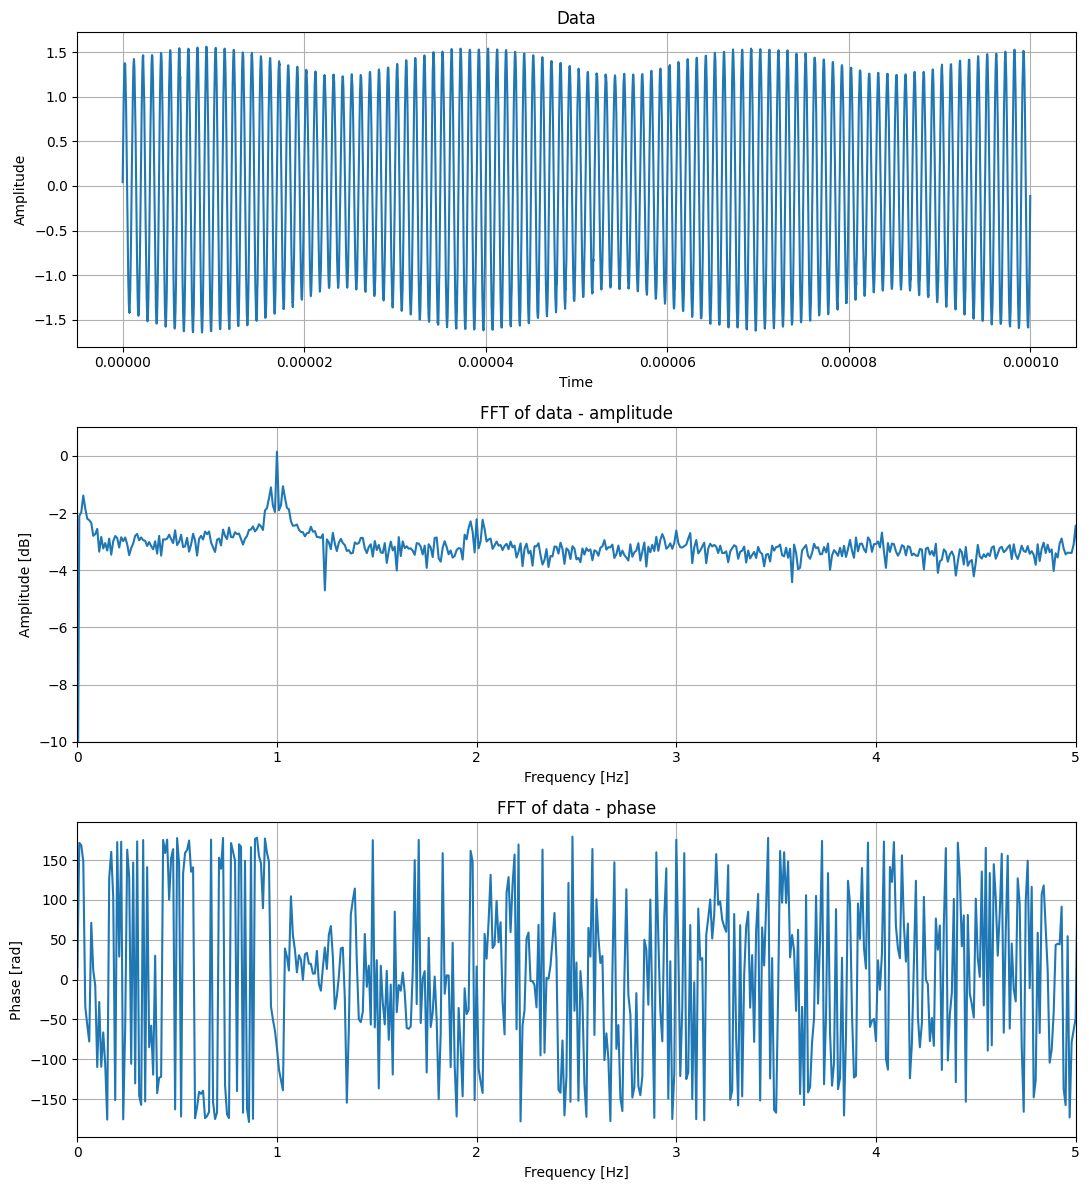

In [386]:
# Plot generated data
fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]
freq /= frequency
# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].plot(
    freq,
    np.log10(np.abs(fft_data)),
    # linefmt="b",
    # markerfmt=" ",
    # basefmt="-b",
    # use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [dB]")
ax[1].set_xlim(0, fft_lim)
ax[1].set_ylim(-10, 1)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, fft_lim)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

Wavelet transform

In [387]:
wpt_df, tr_ob = train.generate_training_data(
    data, levels, wavelet, mode, 
    include_tr_ob=True, min_entropy=use_min_entropy,
    min_level=min_level
)

In [388]:
tr_ob.calc_frequencies(sampling_rate)
tr_ob.info(leaf_nodes=True)

,level,node number,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,3,1,"(3.125e6, 6.25e6)",4687500.0,1.796910,0.254526,0.002803,-2.552332,46.288598,9.096155,1.453287,1.453287,3.414678,7.657444,0.004077
1,3,2,"(9.375e6, 1.25e7)",10937500.0,0.172321,-0.763662,0.000269,-3.570520,6.894433,6.205235,-0.005075,0.005075,5.372862,8.719060,0.000539
2,3,3,"(6.25e6, 9.375e6)",7812500.0,0.245221,-0.610442,0.000383,-3.417300,23.536872,10.145224,1.273588,1.273588,4.857110,8.763155,0.000725
3,3,4,"(2.188e7, 2.5e7)",23437500.0,0.155657,-0.807831,0.000243,-3.614689,3.919664,4.112751,-0.013688,0.013688,5.602624,8.669282,0.000497
4,3,5,"(1.875e7, 2.188e7)",20312500.0,0.131554,-0.880898,0.000205,-3.687756,4.425136,4.993725,0.265254,0.265254,5.573406,8.771997,0.000424
5,3,6,"(1.25e7, 1.562e7)",14062500.0,0.136279,-0.865570,0.000213,-3.672428,4.003194,3.838881,0.093422,0.093422,5.578873,8.800224,0.000439
6,3,7,"(1.562e7, 1.875e7)",17187500.0,0.130693,-0.883748,0.000204,-3.690606,3.749333,3.838714,-0.079622,0.079622,5.599350,8.737378,0.000422
7,4,1,"(1.562e6, 3.125e6)",2343750.0,48.735203,1.687843,0.147682,-0.830671,6.450740,4.296397,0.464605,0.464605,4.792985,5.754526,0.091854
8,5,0,"(0.0, 7.812e5)",390625.0,645.061021,2.809601,3.707247,0.569052,5.718515,3.674943,1.546776,1.546776,3.725958,5.501855,0.744891
9,6,2,"(1.172e6, 1.562e6)",1367187.5,103.849977,2.016406,1.081771,0.034135,13.460248,4.876813,-0.439487,0.439487,2.409642,6.080921,0.130516


In [389]:
# ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.0))
# ax_df2.spines['right'].set_edgecolor('red')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.15))
# ax_df2.spines['right'].set_edgecolor('green')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.3))
# ax_df2.spines['right'].set_edgecolor('cyan')
# wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest factor',c='cyan')

In [390]:
# ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

# ax_df2 = ax_df1.twinx()
# ax_df2.spines['right'].set_position(('axes', 1.0))
# ax_df2.spines['right'].set_edgecolor('red')
# wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest factor',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

In [391]:
# tr_ob.calc_frequencies(sampling_rate)
# plot.heisenberg(tr_ob, max(t_plot))

In [392]:
# wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [393]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, labels, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [394]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training k-means algorithm
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

def train_k_means(wpt_df, classifying_metrics, *, no_clusters=None, use_pca=False):
    """
    Trains a k-means algorithm based on a set of training data given by wpt_df and classifying metrics
    no_clusters can be kept at None to choose an optimal number of clusters by silhouette score.
    use_pca can be set to True to apply pca to the normalised data set before training the algorithm.

    """
    data_train = wpt_df[classifying_metrics]

    scaler = StandardScaler()
    data_train_normalised = scaler.fit_transform(data_train)

    if use_pca is True:
        pca = PCA(n_components=3)
        data_train_normalised = pca.fit_transform(data_train_normalised)    

    if no_clusters is not None:
        kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
        labels = kmeans.fit_predict(data_train_normalised)
    else:
        algorithms = []
        for no_clusters in range(4, 5):
            kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
            labels = kmeans.fit_predict(data_train_normalised)
            silhouette_score = metrics.silhouette_score(data_train_normalised, labels)
            algorithms.append((silhouette_score, kmeans, labels))
        i = max(algorithms, key=lambda x: x[0])
        _, kmeans, labels = i

    centers = kmeans.cluster_centers_
    if use_pca is False:
        centers = scaler.inverse_transform(centers)
        return data_train, labels, data_train_normalised, centers, scaler, kmeans
    if use_pca is True:
        centers = scaler.inverse_transform(pca.inverse_transform(centers))
        return data_train, labels, data_train_normalised, centers, scaler, kmeans, pca


### K-means without PCA

In [395]:
# training data
classifying_metrics = [
    "average energy",
    "kurtosis",
    "crest factor",
    # "log average energy",
    # "level entropy",
    # "spectral entropy"
]
# Set to None to select optimal number of clusters by silhouette score
no_clusters = None
data_train, labels, data_train_normalised, centers, _, kmeans = train_k_means(
    wpt_df, classifying_metrics, no_clusters=no_clusters
)

In [396]:
cluster_ids, cluster_sizes = np.unique(labels, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [8 1 1 1]
cluster IDs: [0 1 2 3]


In [397]:
# fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data', n_runs=100)

3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [398]:
data_train_predict_pca, labels_pca, _, centers_pca, scaler, kmeans_pca, pca = train_k_means(
    wpt_df, classifying_metrics, no_clusters=no_clusters, use_pca=True
)

In [399]:
kmeans_pca.cluster_centers_

array([[-0.28730727, -0.48949502, -0.04256085],
       [ 2.95433464,  1.27125736, -0.62568177],
       [-2.81324982,  2.18390205,  0.12608105],
       [ 2.15737335,  0.46080078,  0.84008753]])

In [400]:
# PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
#              , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

# ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

# ax_pca_df2 = ax_pca_df1.twinx()
# ax_pca_df2.spines['right'].set_position(('axes', 1.0))
# ax_pca_df2.spines['right'].set_edgecolor('red')
# PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')


### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

C:\Users\maxau\AppData\Local\Temp\ipykernel_20300\3040736661.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("Set1")


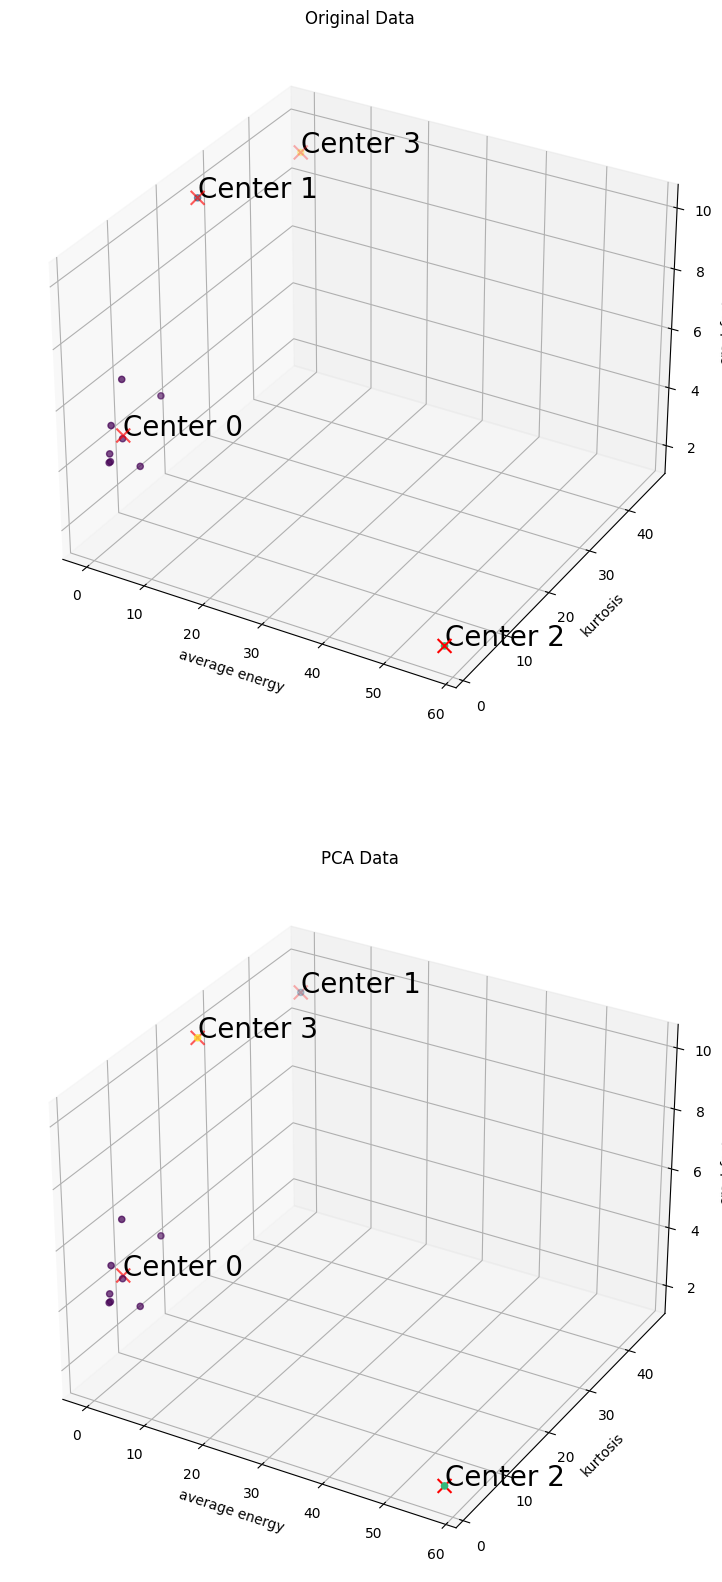

In [401]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = labels
        color_map_labels = labels
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    # Annotate cluster centers with their positions
    for j, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {j}', color='black', fontsize=20)

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

measurement noise:
- kurtosis = 3

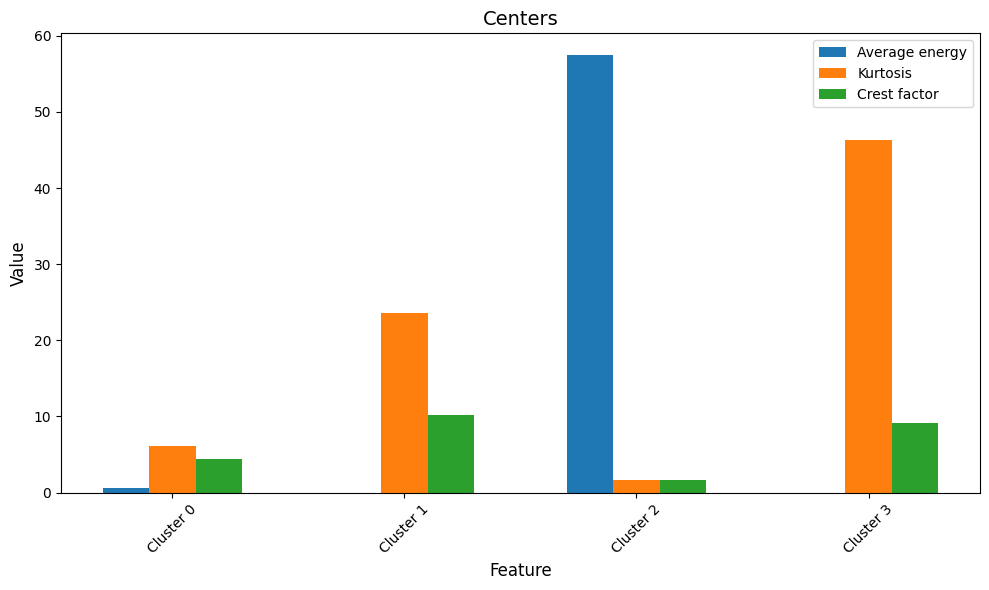

In [402]:
# Swap legend and x-axis?
n_clusters = centers.shape[0]
fig, ax = plt.subplots(figsize=(10, 6))

width = 0.2
x = np.arange(n_clusters)

for i, feature in enumerate(centers.T):
    ax.bar(x + i * width, feature, width, label=f"{classifying_metrics[i]}".capitalize())

ax.set_ylabel("Value", fontsize=12)
ax.set_xlabel("Feature", fontsize=12)
ax.set_title("Centers", fontsize=14)
plt.xticks(
    x + i * width / 2, [f"Cluster {i}" for i in range(n_clusters)], 
    rotation=45, fontsize=10
)
plt.yticks(fontsize=10)

ax.legend(loc='best', fontsize=10)
plt.tight_layout()

plt.show()


### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

In [403]:
display(tr_ob.info(leaf_nodes=True))  # natural order
labels  # natural order

,level,node number,frequency range,centre frequency,energy,log energy,average energy,log average energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,3,1,"(3.125e6, 6.25e6)",4687500.0,1.796910,0.254526,0.002803,-2.552332,46.288598,9.096155,1.453287,1.453287,3.414678,7.657444,0.004077
1,3,2,"(9.375e6, 1.25e7)",10937500.0,0.172321,-0.763662,0.000269,-3.570520,6.894433,6.205235,-0.005075,0.005075,5.372862,8.719060,0.000539
2,3,3,"(6.25e6, 9.375e6)",7812500.0,0.245221,-0.610442,0.000383,-3.417300,23.536872,10.145224,1.273588,1.273588,4.857110,8.763155,0.000725
3,3,4,"(2.188e7, 2.5e7)",23437500.0,0.155657,-0.807831,0.000243,-3.614689,3.919664,4.112751,-0.013688,0.013688,5.602624,8.669282,0.000497
4,3,5,"(1.875e7, 2.188e7)",20312500.0,0.131554,-0.880898,0.000205,-3.687756,4.425136,4.993725,0.265254,0.265254,5.573406,8.771997,0.000424
5,3,6,"(1.25e7, 1.562e7)",14062500.0,0.136279,-0.865570,0.000213,-3.672428,4.003194,3.838881,0.093422,0.093422,5.578873,8.800224,0.000439
6,3,7,"(1.562e7, 1.875e7)",17187500.0,0.130693,-0.883748,0.000204,-3.690606,3.749333,3.838714,-0.079622,0.079622,5.599350,8.737378,0.000422
7,4,1,"(1.562e6, 3.125e6)",2343750.0,48.735203,1.687843,0.147682,-0.830671,6.450740,4.296397,0.464605,0.464605,4.792985,5.754526,0.091854
8,5,0,"(0.0, 7.812e5)",390625.0,645.061021,2.809601,3.707247,0.569052,5.718515,3.674943,1.546776,1.546776,3.725958,5.501855,0.744891
9,6,2,"(1.172e6, 1.562e6)",1367187.5,103.849977,2.016406,1.081771,0.034135,13.460248,4.876813,-0.439487,0.439487,2.409642,6.080921,0.130516


array([3, 0, 1, 0, 0, 0, 0, 0, 0, 0, 2])

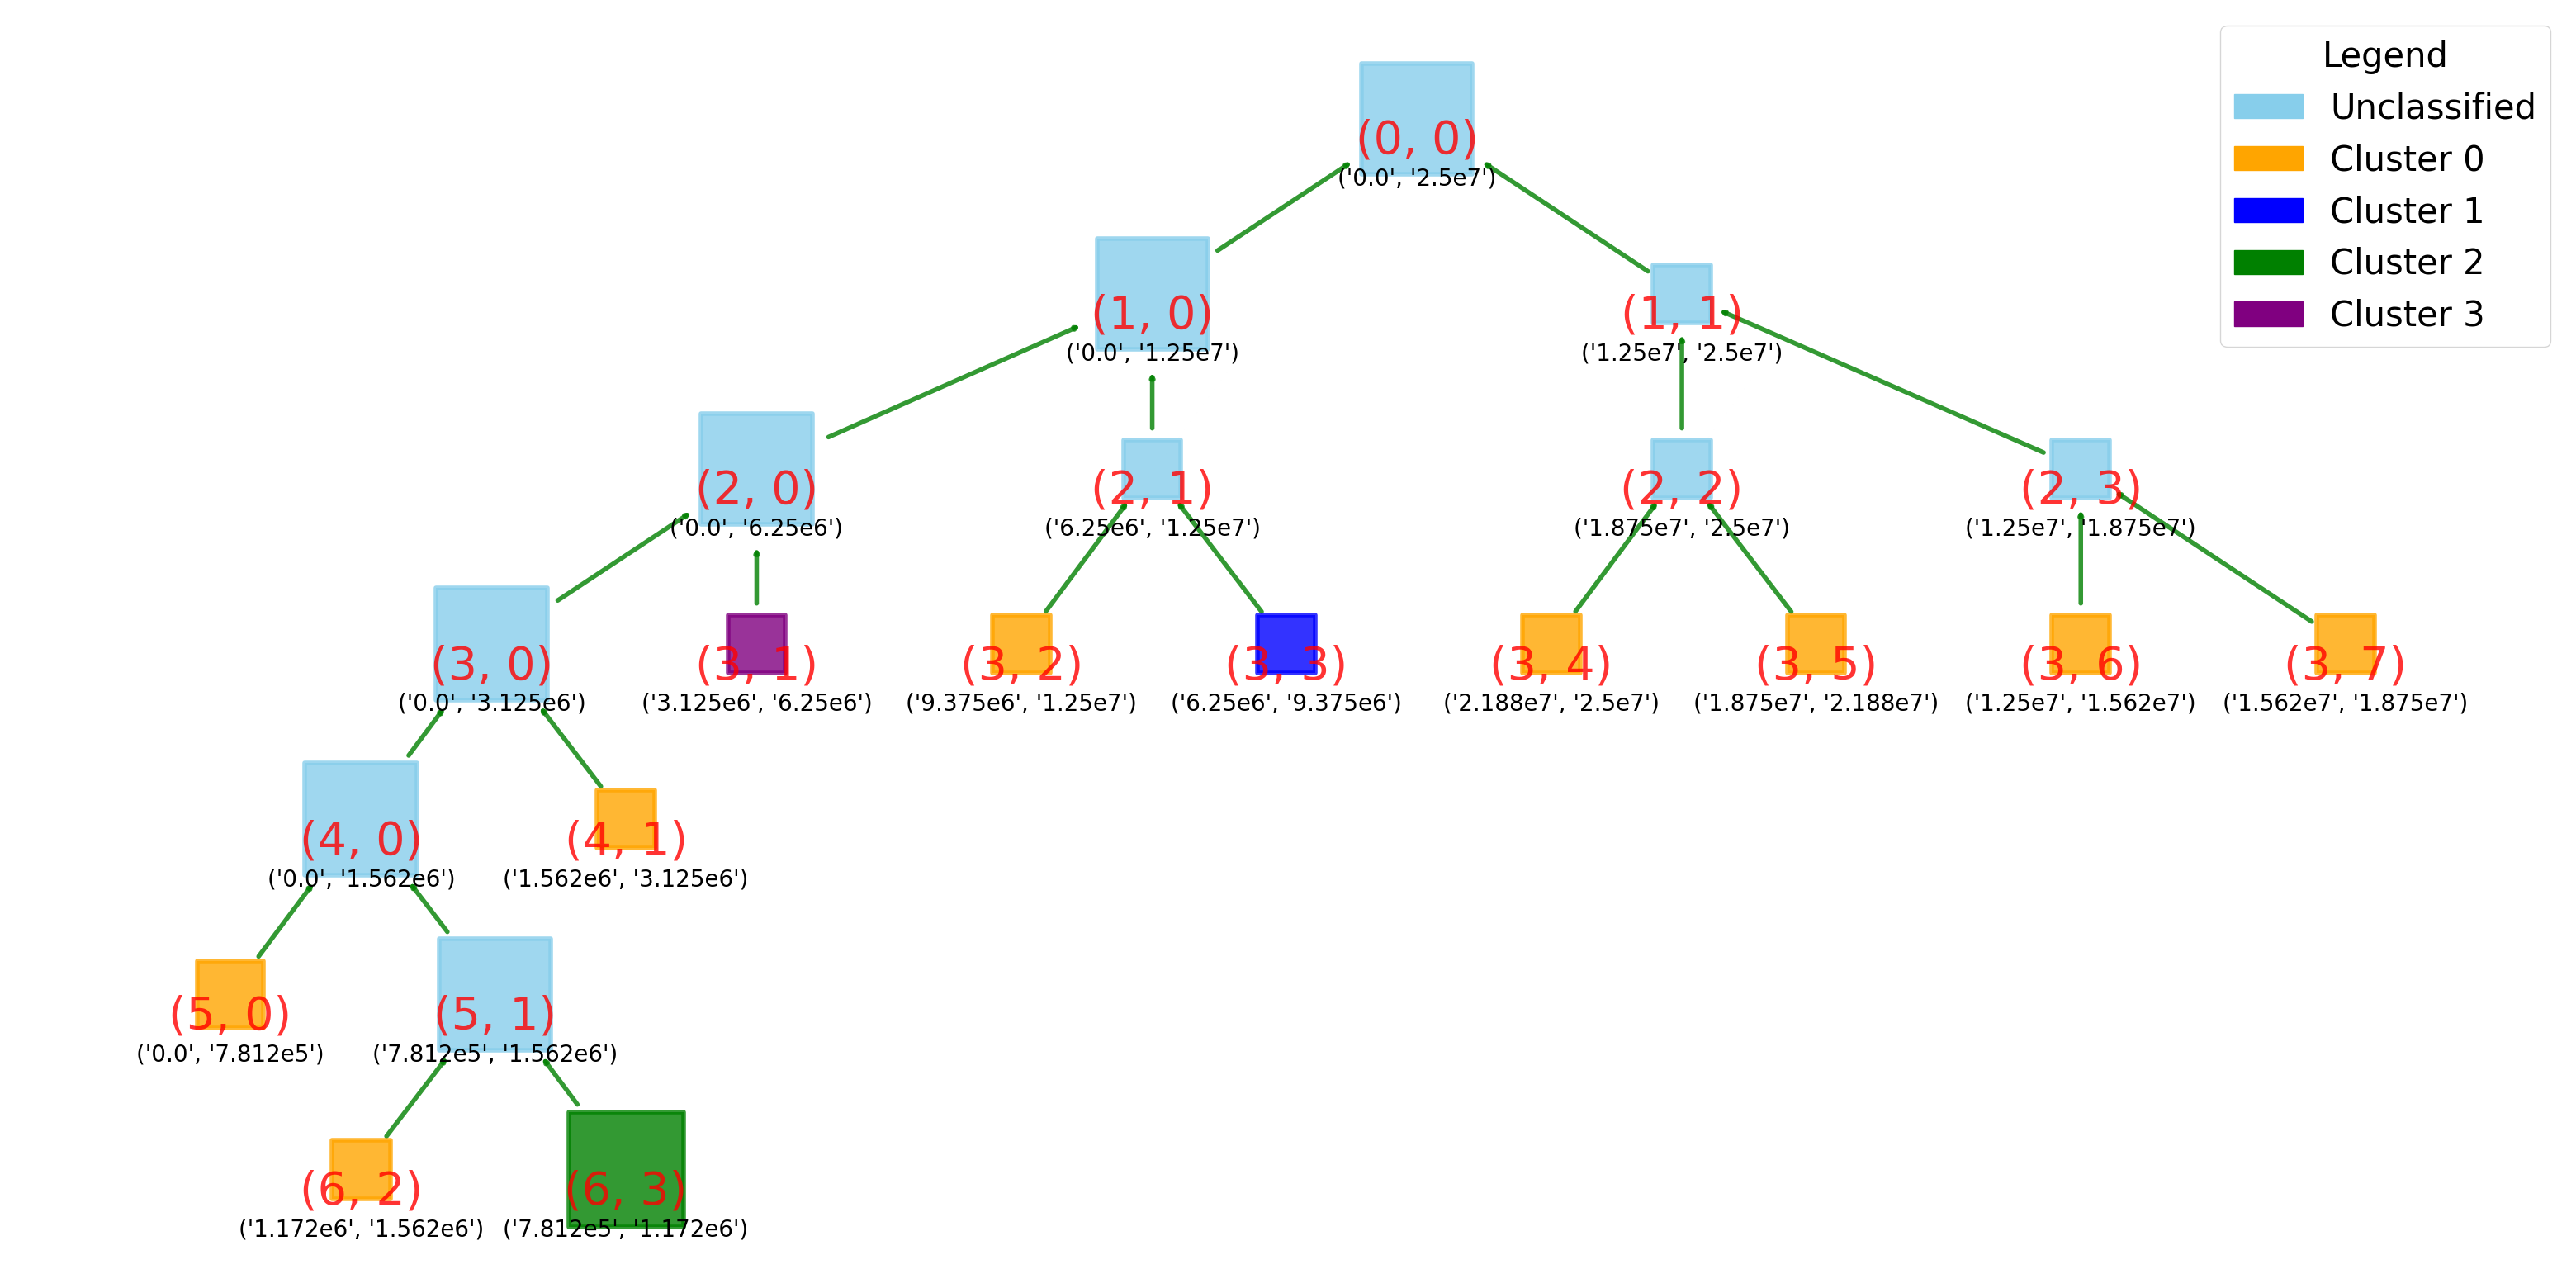

In [404]:
tr_ob.plot_tree(node_size="energy", node_colour=list(labels))

Reconstructed nodes by group:


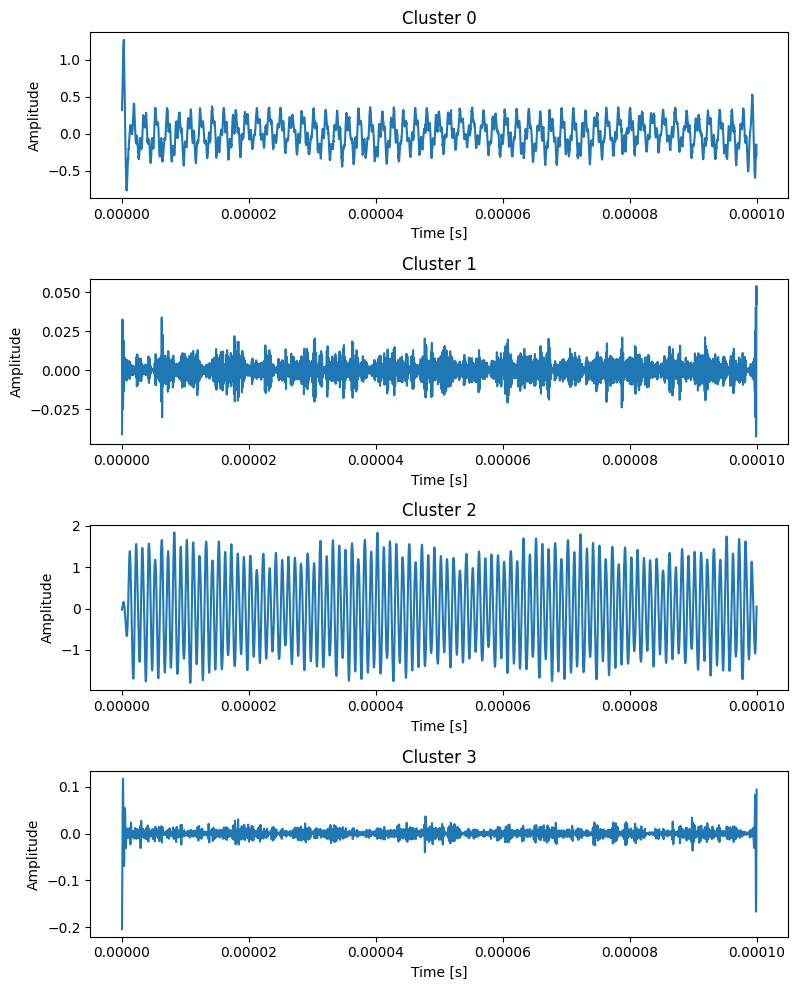

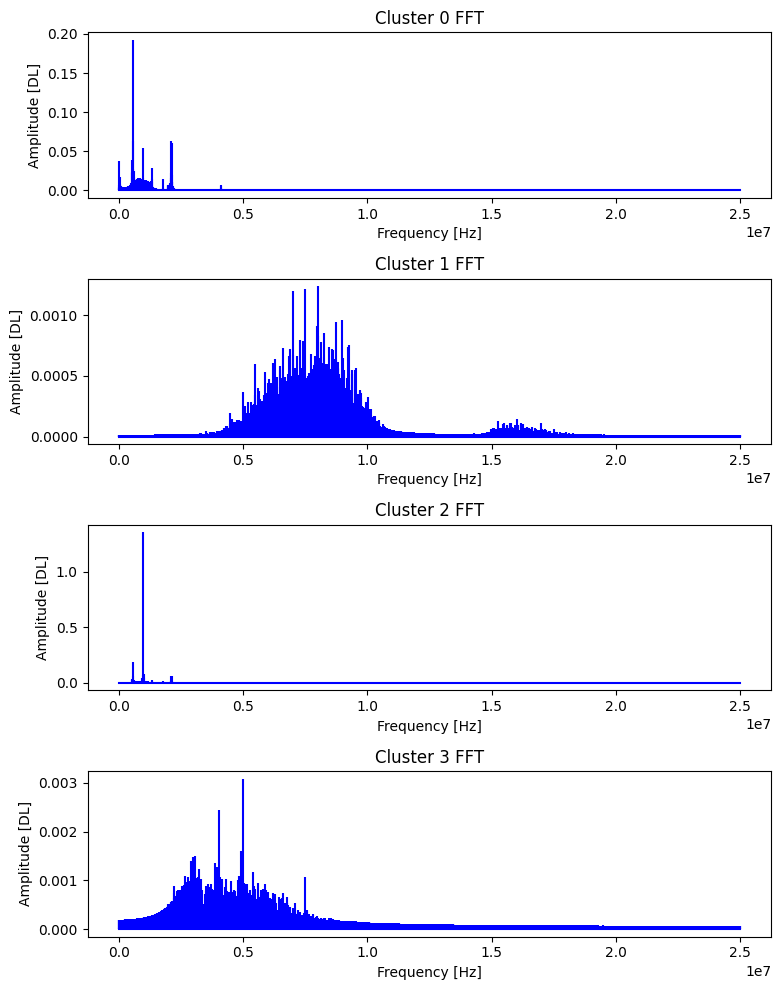

In [405]:
plot.plot_reconstructions_by_group(tr_ob, labels, no_clusters, t_plot, sampling_rate)

In [406]:
# plot pca results
# plot.plot_reconstructions_by_group(tr_ob, labels_pca, no_clusters, t_plot, sampling_rate)

(3125000.0, 6250000.0)


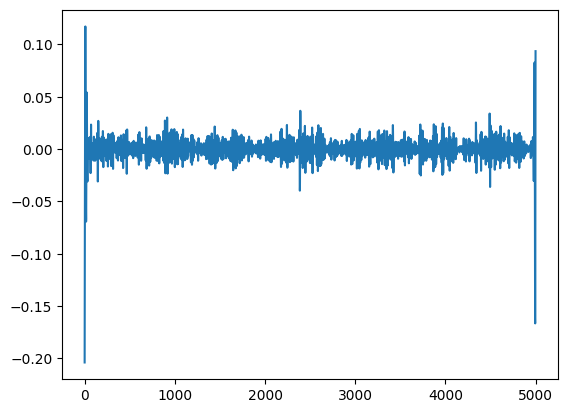

In [407]:
import wavelet_transform.wpt.inverse_transform as inv
run = True
if run is True:
    plot_centres = [3]
    for i, (node, assignment) in enumerate(zip(tr_ob.get_leaf_nodes(), labels)):
        if assignment in plot_centres:
            # print(node.crest_factor)
            print(node.frequency_range)
            rec = inv.inv_dwpt(tr_ob, node.level, nodes=node)
            plt.plot(rec)
            plt.show()

In [408]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["energy"] > THR_Factor * np.max(data_train["energy"])
]
harmonics_data = harmonics_data.sort_values(by="energy", ascending=False)

KeyError: 'energy'

In [ ]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["crest factor"] > THR_Factor * np.max(data_train["crest factor"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

KeyError: 'crest factor'

In [ ]:
print(len(harmonics_data["energy"]))
harmonics_data["frequency range"].values.tolist()

In [ ]:
harmonics_data.plot.bar()

In [ ]:
transient_data.plot.bar()
plt.show()